# Halo burns: NARX prediction versus STM reference

**Goal:** predict how much to change the halo spacecraft’s velocity (**Δv**) and **when to apply the burn**. There is one NARX network and one STM reference. Gateway tracking is left for later post-processing.

### What is STM?

STM means **state transition matrix**. It estimates how a small change now affects the spacecraft’s future orbit. The reference calculation uses it to work out a corrective burn. “STM reference” is what the plots call truth; it is a calculated reference, not a perfect or unique answer.

### The existing burn procedure, in plain language

1. Compare the estimated spacecraft position and velocity with the intended halo orbit.
2. If position departure is **at least 50 km**, **or** velocity departure is **at least 0.5 m/s**, ask for a correction. Otherwise, request no burn.
3. Try four burn times: now, or **22.5°, 45°, or 67.5° later** in the orbit cycle. Here phase is elapsed time through one orbit: 0° to 360°.
4. Use the STM to calculate a Δv for each time. Check each proposed burn by propagating the nonlinear orbit. Reject burns above **10 m/s** or burns that do not reduce the predicted departure. Choose the remaining burn with the lowest departure cost and a small fuel penalty.
5. Apply the chosen burn at its scheduled time. Do not schedule another while one is waiting. If no candidate passes, apply no burn.

This procedure is what the code previously called a **controller**. It is simply how burns are chosen and applied. The decision is checked eight times per halo orbit.

The NARX learns the corresponding burn/no-burn decision, Δv and waiting time from those reference examples. It uses four input-history steps and four past output steps. **All outputs come from one network.** In its orbit test, NARX uses its own predictions; it does not ask STM for replacement burns.

In [1]:
from pathlib import Path
import os, hashlib, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = Path.cwd()
if not (ROOT/'configs').exists(): ROOT = ROOT.parent
os.chdir(ROOT)
from halo_tracking.study import load_config
from halo_tracking.closed_loop_narx import generate_closed_loop_dataset
from halo_tracking.narx_audit import audit_dataset
from halo_tracking.narx_reference import fit_reference_narx, run_reference_pair
cfg = load_config()
cfg['narx']['closed_loop_measurement_cadence_s'] = 21600.
OUT = ROOT/'artifacts'/'narx_stm_comparison'
OUT.mkdir(parents=True, exist_ok=True)
dataset = ROOT/'artifacts'/'neural_narx'/'teacher_training'
nb00 = ROOT/'notebooks'/'00_gateway_tracking_comparison.ipynb'
original_hash = hashlib.sha256(nb00.read_bytes()).hexdigest()
if not all((dataset/(s+'.npz')).exists() for s in ('training','validation','test')):
    generate_closed_loop_dataset(cfg, dataset)
audit = audit_dataset(dataset, cfg)
model, stats = fit_reference_narx(dataset, cfg, OUT, epochs=600)
r = dict(np.load(OUT/'prediction_residuals.npz'))
print('One NARX trained for 600 epochs. Training, validation and test use separate trajectories.')
print('The following plots use the five held-out test trajectories.')
BLUE, ORANGE = 'tab:blue', 'tab:orange'
# Draw separate trajectories without joining their endpoints.
def draw_test_series(ax, values, label, color, **kwargs):
    for a in range(len(r['mask'])):
        use = r['mask'][a]
        ids = np.arange(use.sum()) + a*use.sum()
        ax.plot(ids, values[a,use], color=color, label=label if a==0 else None, **kwargs)
    ax.grid(alpha=.2)

One NARX trained for 600 epochs. Training, validation and test use separate trajectories.
The following plots use the five held-out test trajectories.


## 1. Predicted burn versus STM reference

**Blue is STM; orange is NARX.** The first three panels compare the Δv components. Zero means no burn was requested. The last panel compares burn phase at the STM burn decisions. A red cross marks a burn NARX missed; its timing estimate was not applied. The five separate test trajectories are shown in consecutive blocks.

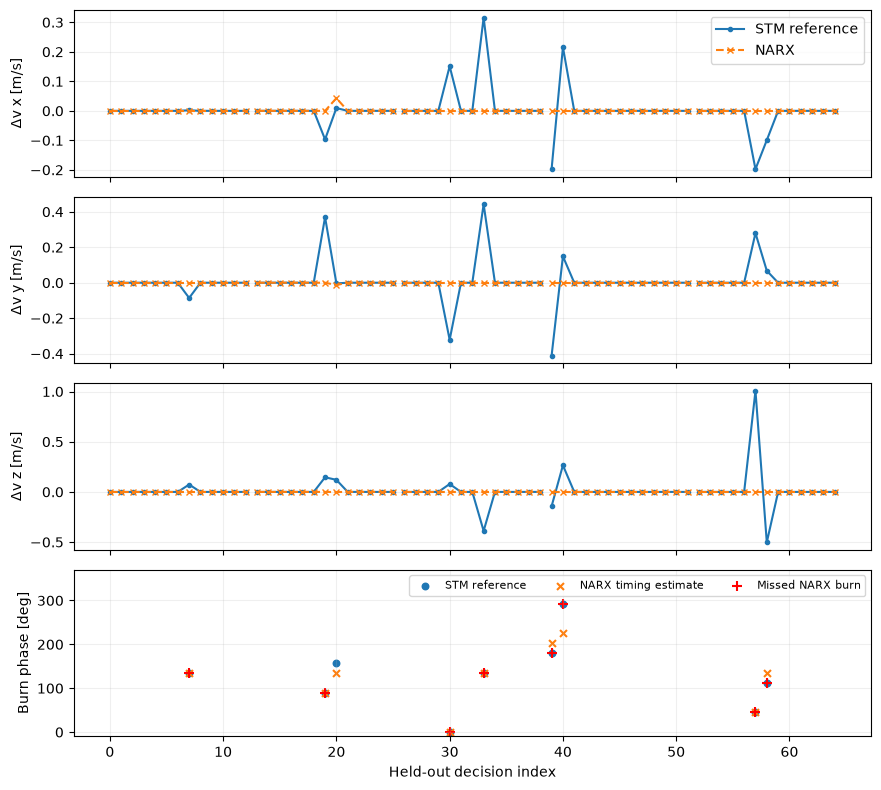

In [2]:
fig, axes = plt.subplots(4,1,figsize=(9,8),sharex=True)
for j,ax in enumerate(axes[:3]):
    draw_test_series(ax,r['reference_delta_v'][...,j],'STM reference',BLUE,marker='o',ms=3)
    draw_test_series(ax,r['predicted_delta_v'][...,j],'NARX',ORANGE,marker='x',ms=4,ls='--')
    ax.set_ylabel(['Δv x [m/s]','Δv y [m/s]','Δv z [m/s]'][j])
axes[0].legend(loc='upper right')
mask = r['mask']; active = mask & r['reference_burn']
flat_ids = np.arange(mask.sum())
ref_phase = r['reference_phase_deg'][mask]
pred_phase = r['predicted_phase_deg'][mask]
burns = active[mask]; missed = burns & ~r['predicted_burn'][mask]
axes[3].scatter(flat_ids[burns],ref_phase[burns],s=22,color=BLUE,label='STM reference')
axes[3].scatter(flat_ids[burns],pred_phase[burns],s=25,color=ORANGE,marker='x',label='NARX timing estimate')
axes[3].scatter(flat_ids[missed],ref_phase[missed],s=60,color='red',marker='+',label='Missed NARX burn')
axes[3].set(ylabel='Burn phase [deg]',xlabel='Held-out decision index',ylim=(-10,370))
axes[3].legend(fontsize=8,ncol=3); axes[3].grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'predicted_vs_stm.png',dpi=100); plt.show()

## 2. Prediction residuals

A **residual** is **NARX minus STM**. Zero is a correct prediction. Positive and negative values show the direction of the error. Phase residuals use the shortest difference around the 0°/360° boundary. Timing errors are assessed at STM burn decisions; missed burns are counted separately below.

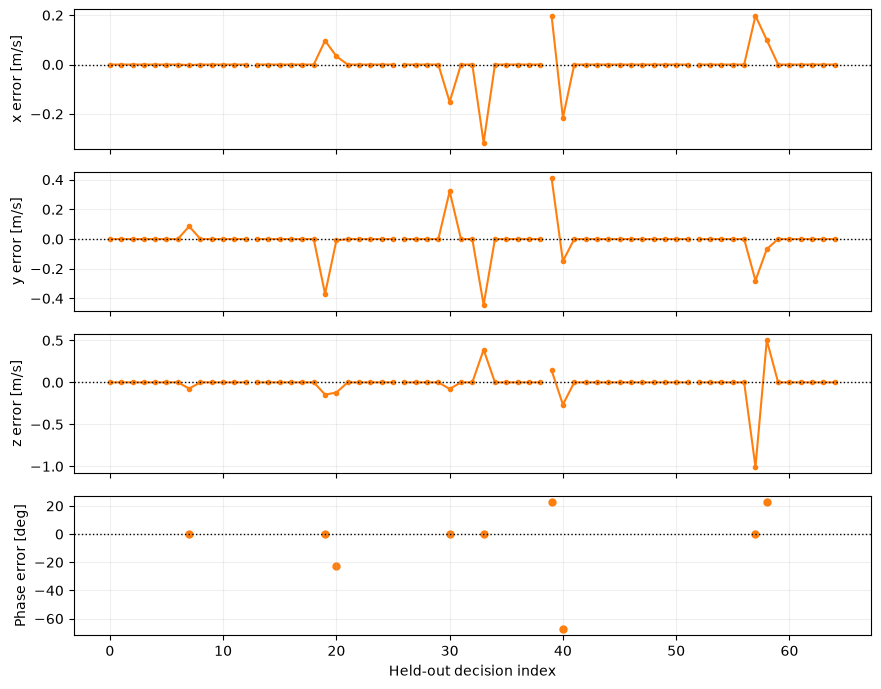

In [3]:
fig, axes = plt.subplots(4,1,figsize=(9,7),sharex=True)
for j,ax in enumerate(axes[:3]):
    draw_test_series(ax,r['delta_v_residual'][...,j],'NARX − STM',ORANGE,marker='o',ms=3)
    ax.axhline(0,color='black',ls=':',lw=1)
    ax.set_ylabel(['x error [m/s]','y error [m/s]','z error [m/s]'][j])
phase_error = r['phase_residual_deg'][mask]
axes[3].scatter(flat_ids[burns],phase_error[burns],color=ORANGE,s=25)
axes[3].axhline(0,color='black',ls=':',lw=1)
axes[3].set(ylabel='Phase error [deg]',xlabel='Held-out decision index')
axes[3].grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'prediction_residuals.png',dpi=100); plt.show()

## 3. What happens to the halo orbit when the burns are applied?

Now run the nonlinear orbit simulation twice: once applying STM burns and once applying NARX burns. Both runs start from the **same state and measurement-noise samples**. The curves show departure from the **same intended halo orbit**; they are not Δv prediction residuals.

The dotted lines are the 100 km and 1 m/s departure limits. STM can exceed them too; finishing the year does not mean staying inside the limits.

The planned span is 365 days. A curve stops if departure exceeds 20,000 km or a numerical failure occurs. Nothing is filled in after it stops. NARX coasts for its first four decisions while its history builds; STM can act from the start. This is one paired trial, not a population success-rate estimate.

STM: {"completed_365_days": true, "completed_requested_span": true, "last_simulated_day": 365.0, "maximum_position_departure_km": 148.91296563672816, "maximum_velocity_departure_m_s": 3.9217118154584036, "corridor_fraction": 0.9285714285714286, "total_delta_v_m_s": 39.80556080902093, "stop_reason": null, "rejected_burns": 0}
NARX: {"completed_365_days": false, "completed_requested_span": false, "last_simulated_day": 42.30488231609435, "maximum_position_departure_km": 22270.77108785058, "maximum_velocity_departure_m_s": 489.8314361768924, "corridor_fraction": 0.013736263736263736, "total_delta_v_m_s": 4.836489691317456, "stop_reason": "departure_cutoff", "rejected_burns": 0}


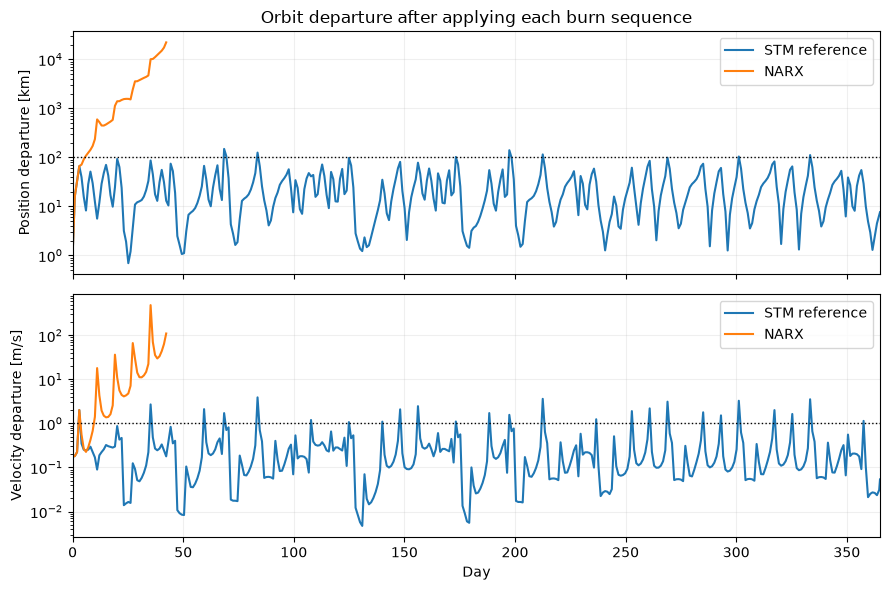

In [4]:
episodes, orbit_stats = run_reference_pair(cfg, model, OUT/'orbit', days=365, seed=24017)
fig, axes = plt.subplots(2,1,figsize=(9,6),sharex=True)
for label,color in [('STM',BLUE),('NARX',ORANGE)]:
    e = episodes[label]
    for ax,key in zip(axes,('observer_truth_position_departure_km','observer_truth_velocity_departure_m_s')):
        ax.plot(e['day'],e[key],color=color,label='STM reference' if label=='STM' else 'NARX')
axes[0].axhline(100,color='black',ls=':',lw=1)
axes[1].axhline(1,color='black',ls=':',lw=1)
axes[0].set(yscale='log',ylabel='Position departure [km]',title='Orbit departure after applying each burn sequence')
axes[1].set(yscale='log',ylabel='Velocity departure [m/s]',xlabel='Day',xlim=(0,365))
for ax in axes: ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'orbit_departure.png',dpi=100); plt.show()

## 4. What do the numbers tell us?

The table counts missed and extra burns, measures Δv error, and checks burn timing. **Vector RMSE** is the typical size of the three-component Δv error, in m/s. Timing accuracy checks the waiting-time estimate at STM burn decisions; it does not mean NARX actually requested those burns.

These statistics describe where this NARX fails. A small training set, missed burns and growing errors are evidence of limitations; they do not prove NARX is unsuitable for every possible dataset.

In [5]:
rows = [
    ('Training decisions containing a burn',f"{stats['training_burns']} / {stats['training_decisions']}"),
    ('STM burns in the held-out test',f"{stats['reference_burns']} / {stats['test_decisions']} decisions"),
    ('STM burns missed by NARX',str(stats['missed_burns'])),
    ('Extra NARX burns',str(stats['extra_burns'])),
    ('Δv vector RMSE on STM burn decisions',f"{stats['burn_vector_rmse_m_s']:.3f} m/s"),
    ('Mean absolute timing error',f"{stats['phase_mean_absolute_error_deg']:.1f}°"),
    ('Correct waiting-time estimate',f"{stats['phase_exact_candidate_accuracy']:.1%}"),
]
display(Markdown('| Check | Result |\n|---|---:|\n'+'\n'.join(f'| {a} | {b} |' for a,b in rows)))
counts = ', '.join(f"{phase:g}°: {count}" for phase,count in zip(stats['phase_candidates_relative_deg'],stats['training_timing_counts']))
display(Markdown('| Waiting phase | Training burns | Test burns |\n|---|---:|---:|\n'+'\n'.join(
    f'| {phase:g}° | {train} | {test} |' for phase,train,test in zip(
        stats['phase_candidates_relative_deg'],stats['training_timing_counts'],stats['test_timing_counts']))))
unseen_test = sum(test for train,test in zip(stats['training_timing_counts'],stats['test_timing_counts']) if train==0)
print(f'{unseen_test} test burns use a waiting phase with no training burn examples.')
for label in ('STM','NARX'):
    q = orbit_stats[label]
    print(f"{label}: last simulated day {q['last_simulated_day']:.1f}; stop reason: {q['stop_reason'] or 'completed 365 days'}.")
display(Markdown(f"**Observed limitation:** NARX missed {stats['missed_burns']} of {stats['reference_burns']} reference burns on the held-out inputs. A reasonable timing estimate cannot compensate for a burn that is never requested. Training includes only {stats['training_burns']} usable burn examples, and the phase counts above show which timings are represented. The orbit test then measures the consequence of applying NARX’s own burns."))
first_far = orbit_stats['diagnostics']['first_day_above_10_standard_deviations']
if first_far is not None:
    print(f'From day {first_far:.1f}, some NARX inputs are more than ten training standard deviations from their training mean. Later predictions therefore use inputs far from typical training values; this does not prove the cause of the first failure.')
assert hashlib.sha256(nb00.read_bytes()).hexdigest() == original_hash
(OUT/'audit.json').write_text(json.dumps(audit,indent=2)+'\n')
print('Notebook 00 is unchanged. All three figures and their underlying results are saved.')

2 test burns use a waiting phase with no training burn examples.
STM: last simulated day 365.0; stop reason: completed 365 days.
NARX: last simulated day 42.3; stop reason: departure_cutoff.
From day 11.1, some NARX inputs are more than ten training standard deviations from their training mean. Later predictions therefore use inputs far from typical training values; this does not prove the cause of the first failure.
Notebook 00 is unchanged. All three figures and their underlying results are saved.


| Check | Result |
|---|---:|
| Training decisions containing a burn | 41 / 260 |
| STM burns in the held-out test | 9 / 65 decisions |
| STM burns missed by NARX | 8 |
| Extra NARX burns | 0 |
| Δv vector RMSE on STM burn decisions | 0.531 m/s |
| Mean absolute timing error | 15.0° |
| Correct waiting-time estimate | 55.6% |

| Waiting phase | Training burns | Test burns |
|---|---:|---:|
| 0° | 31 | 6 |
| 22.5° | 0 | 2 |
| 45° | 0 | 0 |
| 67.5° | 10 | 1 |

**Observed limitation:** NARX missed 8 of 9 reference burns on the held-out inputs. A reasonable timing estimate cannot compensate for a burn that is never requested. Training includes only 41 usable burn examples, and the phase counts above show which timings are represented. The orbit test then measures the consequence of applying NARX’s own burns.